🚀 Iniciando Ingesta y Pipeline de EDA a gran escala...
🎯 Dataset unificado con éxito. Iniciando análisis cuantitativo...

📊 DIAGNÓSTICO DE LA VARIABLE OBJETIVO (RISK PROFILE)
• Total de Solicitudes Evaluadas: 1,526,659
• Clientes que Cumplieron sus Pagos (Target=0): 1,478,665 (96.86%)
• Clientes en Incumplimiento/Impago (Target=1): 47,994 (3.14%)
• Tasa de Default Global de la Cartera: 3.14%



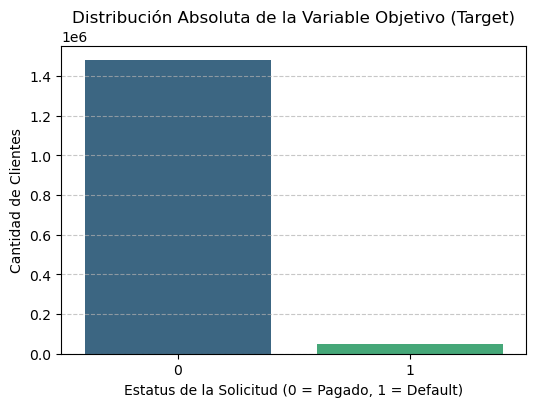

⏱️ ANALIZANDO ESTABILIDAD DEL RIESGO EN EL TIEMPO
   WEEK_NUM  total_solicitudes  tasa_default
0         0              16735      2.390200
1         1              18841      2.505175
2         2              17476      2.660792
3         3              16108      2.601192
4         4              14309      2.823398
5         5              15335      2.654059
6         6              16385      2.715899
7         7              17238      2.680125
8         8              13076      3.242582
9         9              14716      2.650177


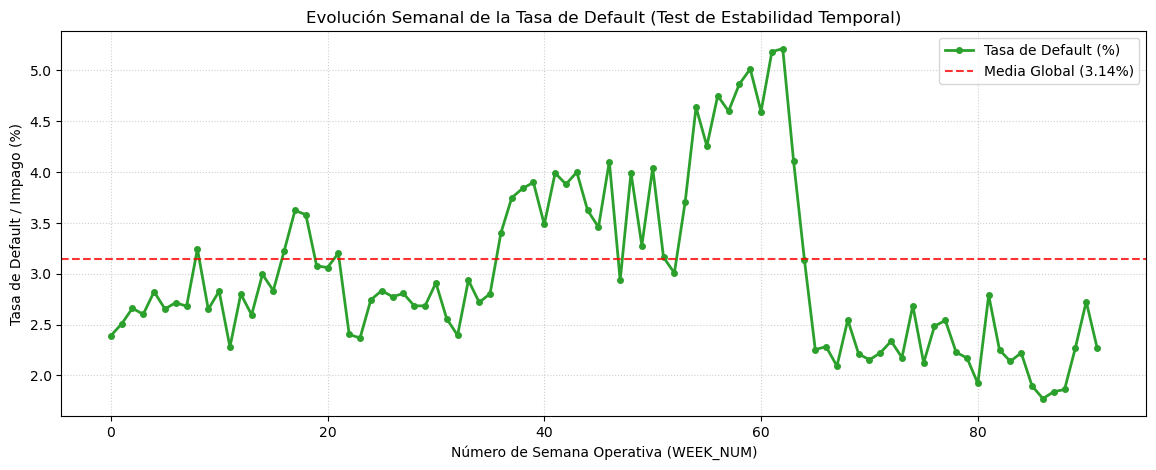

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import gc

PATH_DATOS = "../../home-credit-credit-risk-model-stability/train/"

print("🚀 Iniciando Ingesta y Pipeline de EDA a gran escala...")

base_train = pd.read_parquet(os.path.join(PATH_DATOS, "train_base.parquet"))
static_0_0 = pd.read_parquet(os.path.join(PATH_DATOS, "train_static_0_0.parquet"))

df_eda = pd.merge(base_train, static_0_0, on="case_id", how="left")

del base_train, static_0_0
gc.collect()

print("🎯 Dataset unificado con éxito. Iniciando análisis cuantitativo...\n")

total_casos = len(df_eda)
buenos_pagadores = df_eda['target'].value_counts()[0]
defaults = df_eda['target'].value_counts()[1]
tasa_default_gen = (defaults / total_casos) * 100

print("====================================================================")
print("📊 DIAGNÓSTICO DE LA VARIABLE OBJETIVO (RISK PROFILE)")
print("====================================================================")
print(f"• Total de Solicitudes Evaluadas: {total_casos:,}")
print(f"• Clientes que Cumplieron sus Pagos (Target=0): {buenos_pagadores:,} ({buenos_pagadores/total_casos*100:.2f}%)")
print(f"• Clientes en Incumplimiento/Impago (Target=1): {defaults:,} ({defaults/total_casos*100:.2f}%)")
print(f"• Tasa de Default Global de la Cartera: {tasa_default_gen:.2f}%")
print("====================================================================\n")

plt.figure(figsize=(6, 4))
sns.countplot(data=df_eda, x='target', hue='target', palette='viridis', legend=False)
plt.title('Distribución Absoluta de la Variable Objetivo (Target)')
plt.xlabel('Estatus de la Solicitud (0 = Pagado, 1 = Default)')
plt.ylabel('Cantidad de Clientes')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print("====================================================================")
print("⏱️ ANALIZANDO ESTABILIDAD DEL RIESGO EN EL TIEMPO")
print("====================================================================")

analisis_temporal = df_eda.groupby('WEEK_NUM').agg(
    total_solicitudes=('target', 'count'),
    tasa_default=('target', 'mean')
).reset_index()

analisis_temporal['tasa_default'] *= 100

print(analisis_temporal.head(10))

plt.figure(figsize=(14, 5))
plt.plot(analisis_temporal['WEEK_NUM'], analisis_temporal['tasa_default'], 
         color='#2ca02c', linewidth=2, marker='o', markersize=4, label='Tasa de Default (%)')
plt.axhline(y=tasa_default_gen, color='red', linestyle='--', alpha=0.8, 
            label=f'Media Global ({tasa_default_gen:.2f}%)')
plt.title('Evolución Semanal de la Tasa de Default (Test de Estabilidad Temporal)')
plt.xlabel('Número de Semana Operativa (WEEK_NUM)')
plt.ylabel('Tasa de Default / Impago (%)')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [2]:
columnas_interes = [col for col in df_eda.columns if any(keyword in col.lower() for keyword in ['amt', 'income', 'age', 'child', 'status', 'person'])]
print("🔍 Variables estáticas detectadas candidatas para análisis de Inclusión/Fairness:")
for c in columnas_interes[:20]:
    print(f"• {c}")

🔍 Variables estáticas detectadas candidatas para análisis de Inclusión/Fairness:
• amtinstpaidbefduel24m_4187115A
• avglnamtstart24m_4525187A
• maxlnamtstart6m_4525199A


In [3]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

In [4]:
inventario_variables = pd.DataFrame({
    'Tipo_Dato': df_eda.dtypes,
    'Valores_Nulos(NaN)': df_eda.isnull().sum(),
    'Porcentaje_Nulos(%)': (df_eda.isnull().sum() / len(df_eda)) * 100,
    'Primer_Valor_Real': df_eda.apply(lambda x: x.dropna().iloc[0] if len(x.dropna()) > 0 else np.nan)
})
inventario_variables['Porcentaje_Nulos(%)'] = inventario_variables['Porcentaje_Nulos(%)'].round(2)
print(f"\n📋 INVENTARIO COMPLETO DE VARIABLES DISPONIBLES EN TU PIPELINE:")
display(inventario_variables)


📋 INVENTARIO COMPLETO DE VARIABLES DISPONIBLES EN TU PIPELINE:


,Tipo_Dato,Valores_Nulos(NaN),Porcentaje_Nulos(%),Primer_Valor_Real
case_id,int64,0,0.00,0
date_decision,str,0,0.00,2019-01-03
MONTH,int64,0,0.00,201901
WEEK_NUM,int64,0,0.00,0
target,int64,0,0.00,0
actualdpdtolerance_344P,float64,819588,53.69,0.0
amtinstpaidbefduel24m_4187115A,float64,951756,62.34,7374.0
annuity_780A,float64,522902,34.25,1917.6
annuitynextmonth_57A,float64,522904,34.25,0.0
applicationcnt_361L,float64,522902,34.25,0.0



📊 Corriendo Análisis 1: Ingreso Principal vs Estatus de Impago...


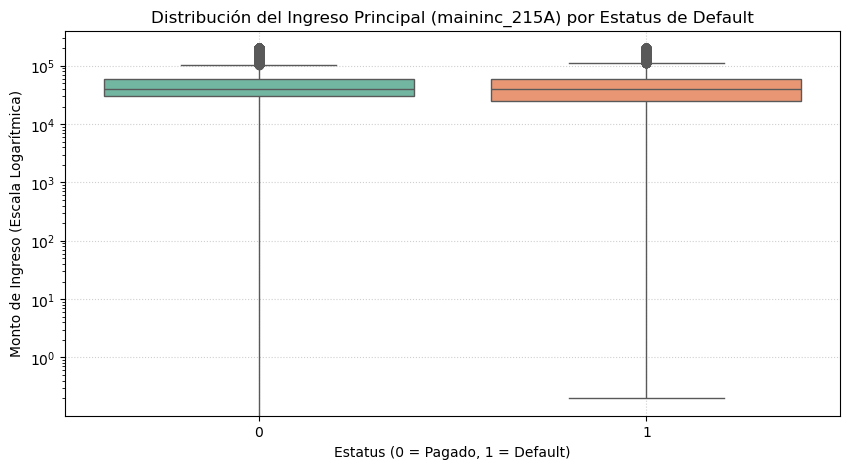

In [5]:
print("\n📊 Corriendo Análisis 1: Ingreso Principal vs Estatus de Impago...")

plt.figure(figsize=(10, 5))
# Filtramos los nulos y aplicamos escala logarítmica por la asimetría de ingresos
sns.boxplot(
    data=df_eda.dropna(subset=['maininc_215A']), 
    x='target', 
    y='maininc_215A', 
    hue='target',
    palette='Set2', 
    legend=False
)
plt.yscale('log')
plt.title('Distribución del Ingreso Principal (maininc_215A) por Estatus de Default')
plt.xlabel('Estatus (0 = Pagado, 1 = Default)')
plt.ylabel('Monto de Ingreso (Escala Logarítmica)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

📊 Corriendo Análisis 2: Disciplina de Pagos Anticipados...


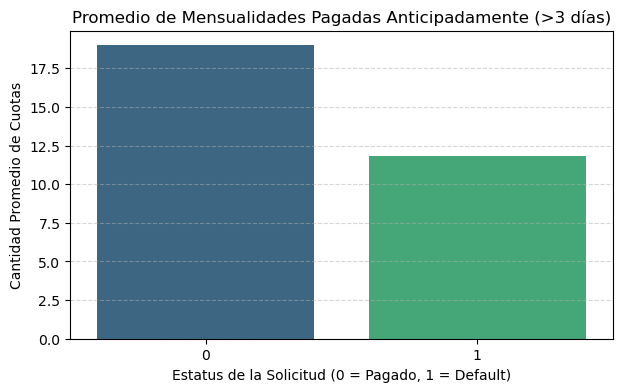


🧹 Pipeline de visualización terminado. RAM liberada.


In [6]:
print("📊 Corriendo Análisis 2: Disciplina de Pagos Anticipados...")

# Agrupamos por target para ver la media de mensualidades pagadas con >3 días de anticipación
disciplina_pago = df_eda.groupby('target')['numinstpaidearly3d_3546850L'].mean().reset_index()

plt.figure(figsize=(7, 4))
sns.barplot(
    data=disciplina_pago, 
    x='target', 
    y='numinstpaidearly3d_3546850L', 
    hue='target',
    palette='viridis', 
    legend=False
)
plt.title('Promedio de Mensualidades Pagadas Anticipadamente (>3 días)')
plt.xlabel('Estatus de la Solicitud (0 = Pagado, 1 = Default)')
plt.ylabel('Cantidad Promedio de Cuotas')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

print("\n🧹 Pipeline de visualización terminado. RAM liberada.")

In [7]:
df_eda['ingreso_es_nulo'] = df_eda['maininc_215A'].isnull().astype(int)

# Calcular la tasa de default para los que NO registraron ingresos vs los que SÍ
reporte_nulos = df_eda.groupby('ingreso_es_nulo').agg(
    total_clientes=('target', 'count'),
    tasa_default_porcentaje=('target', lambda x: x.mean() * 100)
).reset_index()

print("====================================================================")
print("🔍 AUDITORÍA DE VALORES NULOS EN INGRESO (BIAS DETECTION)")
print("====================================================================")
print(reporte_nulos.to_string(index=False, formatters={
    'total_clientes': '{:,.0f}'.format,
    'tasa_default_porcentaje': '{:.2f}%'.format
}))
print("====================================================================")

🔍 AUDITORÍA DE VALORES NULOS EN INGRESO (BIAS DETECTION)
 ingreso_es_nulo total_clientes tasa_default_porcentaje
               0        662,807                   3.13%
               1        863,852                   3.15%


In [8]:
# Analizar la disciplina de pago adelantado en función de si tienen ingreso o no
reporte_compensacion = df_eda.groupby('ingreso_es_nulo').agg(
    total_clientes=('target', 'count'),
    promedio_pagos_adelantados=('numinstpaidearly3d_3546850L', 'mean'),
    tasa_default_porcentaje=('target', lambda x: x.mean() * 100)
).reset_index()

print("====================================================================")
print("📈 TRANSACCIONALIDAD ALTERNATIVA COMO COMPENSACIÓN DE INGRESO")
print("====================================================================")
print(reporte_compensacion.to_string(index=False, formatters={
    'total_clientes': '{:,.0f}'.format,
    'promedio_pagos_adelantados': '{:.1f}'.format,
    'tasa_default_porcentaje': '{:.2f}%'.format
}))
print("====================================================================")

📈 TRANSACCIONALIDAD ALTERNATIVA COMO COMPENSACIÓN DE INGRESO
 ingreso_es_nulo total_clientes promedio_pagos_adelantados tasa_default_porcentaje
               0        662,807                       18.8                   3.13%
               1        863,852                       18.5                   3.15%



📊 Análisis de Percentiles de Endeudamiento para Clientes en Default vs Sanos:

📈 [Tabla 1] Percentiles del Monto de Crédito Solicitado (credamount_770A):


,Percentil 50 (Mediana),Percentil 75,Percentil 90
target,,,
0,"33,796.00","60,000.00","100,000.00"
1,"33,918.00","67,794.00","115,786.00"


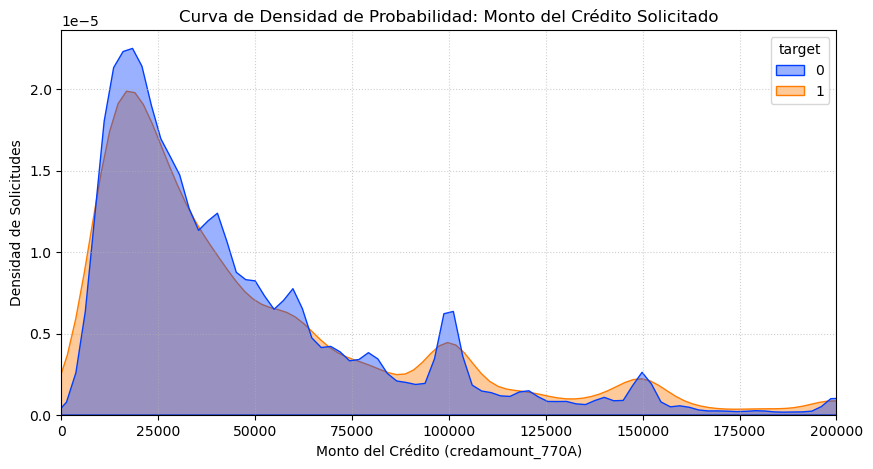

In [9]:
print("\n📊 Análisis de Percentiles de Endeudamiento para Clientes en Default vs Sanos:")

# Calculamos los percentiles 50 (mediana), 75 y 90 para el monto del crédito actual
percentiles_credito = df_eda.groupby('target')['credamount_770A'].quantile([0.5, 0.75, 0.90]).unstack()
percentiles_credito.columns = ['Percentil 50 (Mediana)', 'Percentil 75', 'Percentil 90']

print("\n📈 [Tabla 1] Percentiles del Monto de Crédito Solicitado (credamount_770A):")
display(percentiles_credito.style.format('{:,.2f}'))

# Visualización de la Densidad del Crédito Solicitado (Focalizado en el grueso de la población)
plt.figure(figsize=(10, 5))
sns.kdeplot(data=df_eda, x='credamount_770A', hue='target', common_norm=False, fill=True, palette='bright', alpha=0.4)
plt.xlim(0, 200000) # Acotamos el eje X para evitar que los outliers estiren el gráfico
plt.title('Curva de Densidad de Probabilidad: Monto del Crédito Solicitado')
plt.xlabel('Monto del Crédito (credamount_770A)')
plt.ylabel('Densidad de Solicitudes')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


📋 [TABLA DESCRIPTIVA] Caracterización de la Cartera por Perfil de Riesgo:



🔍 [AUDITORÍA DE OUTLIERS] Coeficientes de Asimetría (Skewness):
(Un valor > 3 indica asimetría extrema derecha; requiere transformación no lineal ln)
• Variable 'credamount_770A': Coeficiente de Asimetría = 2.18
• Variable 'maininc_215A': Coeficiente de Asimetría = 1.82
• Variable 'annuity_780A': Coeficiente de Asimetría = 2.58
• Variable 'numinstpaidearly3d_3546850L': Coeficiente de Asimetría = 2.68
• Variable 'numinstlswithoutdpd_562L': Coeficiente de Asimetría = 2.23

🚨 [TEST DE MULTICOLINEALIDAD] Calculando Matriz de Correlación de Pearson...


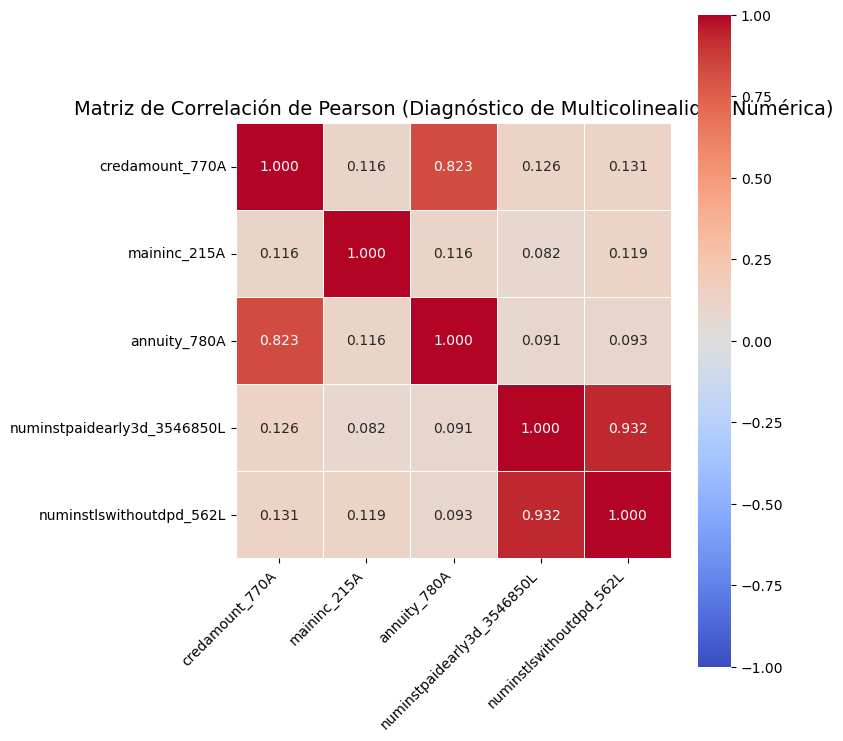


🧹 Pruebas de diagnóstico terminadas. RAM optimizada.


In [10]:
variables_numericas = [
    'credamount_770A',                # Monto solicitado
    'maininc_215A',                   # Ingreso declarado
    'annuity_780A',                   # Mensualidad propuesta
    'numinstpaidearly3d_3546850L',    # Historial transaccional alternativo
    'numinstlswithoutdpd_562L'        # Cuotas pagadas perfectamente a tiempo
]
print("\n📋 [TABLA DESCRIPTIVA] Caracterización de la Cartera por Perfil de Riesgo:")

# Usamos un groupby sobre el target para ver las métricas descriptivas tradicionales
descriptivos_riesgo = df_eda.groupby('target')[variables_numericas].agg(
    ['count', 'mean', 'std', 'median']
).T.swaplevel(0, 1).sort_index()

# Formateamos con display de Jupyter para que luzca impecable en tu reporte
display(descriptivos_riesgo.style.format('{:,.2f}'))

print("\n🔍 [AUDITORÍA DE OUTLIERS] Coeficientes de Asimetría (Skewness):")
print("(Un valor > 3 indica asimetría extrema derecha; requiere transformación no lineal ln)")

for var in variables_numericas:
    skew_val = df_eda[var].skew()
    print(f"• Variable '{var}': Coeficiente de Asimetría = {skew_val:.2f}")

print("\n🚨 [TEST DE MULTICOLINEALIDAD] Calculando Matriz de Correlación de Pearson...")

# Calculamos las correlaciones sobre las variables seleccionadas (omitiendo nulos de forma nativa)
matriz_corr = df_eda[variables_numericas].corr()

# Graficamos el mapa de calor con diseño corporativo
plt.figure(figsize=(8, 8))
sns.heatmap(
    matriz_corr, 
    annot=True, 
    cmap='coolwarm', 
    fmt=".3f", 
    linewidths=.5, 
    vmin=-1, vmax=1,
    square=True
)
plt.title('Matriz de Correlación de Pearson (Diagnóstico de Multicolinealidad Numérica)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\n🧹 Pruebas de diagnóstico terminadas. RAM optimizada.")

📈 TRATAMIENTO DE MULTICOLINEALIDAD (FEATURE ENGINEERING)
            mean       std       50%
target                              
0       0.097890  0.045824  0.083416
1       0.097151  0.045629  0.083462

🗂️ ANÁLISIS DE VARIABLES CATEGÓRICAS: TIPO DE CRÉDITO (credtype_322L)
credtype_322L total_credits tasa_default_credits
          CAL       216,313                3.21%
          COL       661,574                3.05%
          REL       125,869                2.88%

bankacctype_710L total_ctas tasa_default_ctas
              CA    304,690             2.90%

disbursementtype_67L total_desembolso tasa_default_desembolso
                  DD           28,104                   3.84%
                 GBA          216,233                   3.21%
                 SBA          758,802                   2.99%



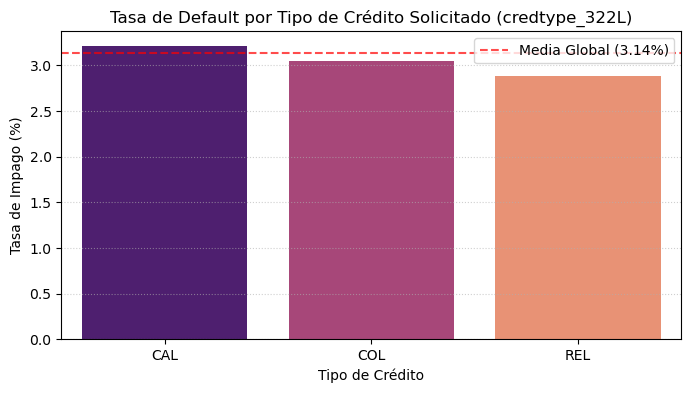

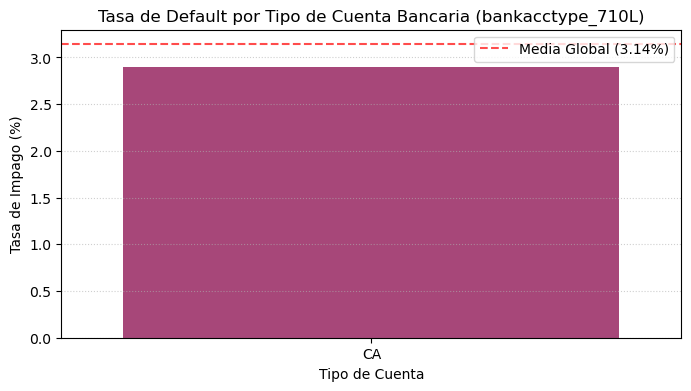

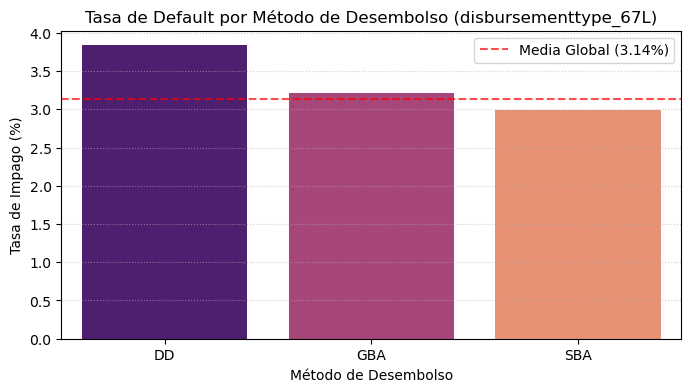

📊 Generando curva de interacción bidimensional para reporte...


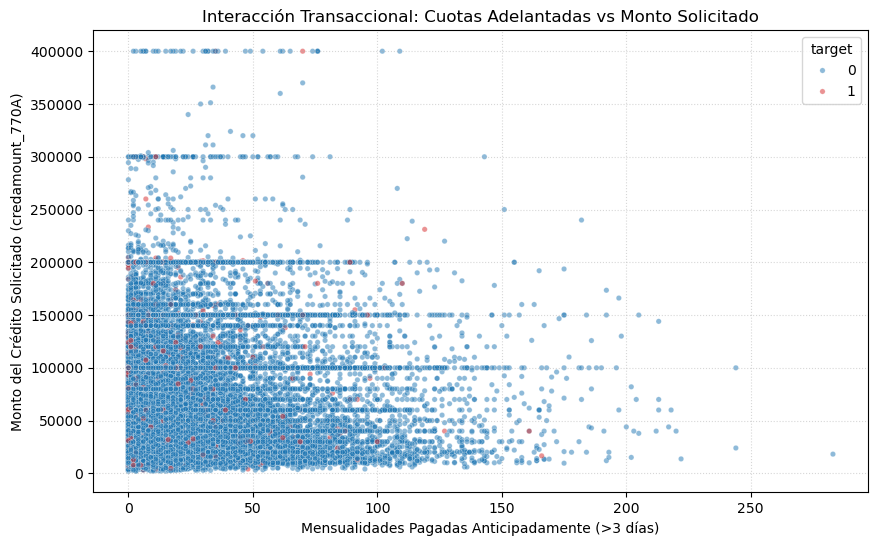

🧹 Pipeline de EDA avanzado concluido.


In [11]:
df_eda['annuity_to_amt_ratio'] = df_eda['annuity_780A'] / df_eda['credamount_770A']

print("====================================================================")
print("📈 TRATAMIENTO DE MULTICOLINEALIDAD (FEATURE ENGINEERING)")
print("====================================================================")
print(df_eda.groupby('target')['annuity_to_amt_ratio'].describe()[['mean', 'std', '50%']])
print("====================================================================\n")

print("====================================================================")
print("🗂️ ANÁLISIS DE VARIABLES CATEGÓRICAS: TIPO DE CRÉDITO (credtype_322L)")
print("====================================================================")

# Calculamos distribución de frecuencias y tasa de default por tipo de crédito
reporte_tpcred = df_eda.groupby('credtype_322L').agg(
    total_credits=('target', 'count'),
    tasa_default_credits=('target', lambda x: x.mean() * 100)
).reset_index()

print(reporte_tpcred.to_string(index=False, formatters={
    'total_credits': '{:,.0f}'.format,
    'tasa_default_credits': '{:.2f}%'.format
}))
print("====================================================================\n")

reporte_tpcta = df_eda.groupby('bankacctype_710L').agg(
    total_ctas=('target', 'count'),
    tasa_default_ctas=('target', lambda x: x.mean() * 100)
).reset_index()

print(reporte_tpcta.to_string(index=False, formatters={
    'total_ctas': '{:,.0f}'.format,
    'tasa_default_ctas': '{:.2f}%'.format
}))
print("====================================================================\n")

reporte_desembolso = df_eda.groupby('disbursementtype_67L').agg(
    total_desembolso=('target', 'count'),
    tasa_default_desembolso=('target', lambda x: x.mean() * 100)
).reset_index()

print(reporte_desembolso.to_string(index=False, formatters={
    'total_desembolso': '{:,.0f}'.format,
    'tasa_default_desembolso': '{:.2f}%'.format
}))
print("====================================================================\n")


plt.figure(figsize=(8, 4))
sns.barplot(
    data=reporte_tpcred, 
    x='credtype_322L', 
    y='tasa_default_credits', 
    hue='credtype_322L',
    palette='magma',
    legend=False
)
plt.axhline(y=3.14, color='red', linestyle='--', alpha=0.7, label='Media Global (3.14%)')
plt.title('Tasa de Default por Tipo de Crédito Solicitado (credtype_322L)')
plt.xlabel('Tipo de Crédito')
plt.ylabel('Tasa de Impago (%)')
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

plt.figure(figsize=(8, 4))
sns.barplot(
    data=reporte_tpcta, 
    x='bankacctype_710L', 
    y='tasa_default_ctas', 
    hue='bankacctype_710L',
    palette='magma',
    legend=False
)
plt.axhline(y=3.14, color='red', linestyle='--', alpha=0.7, label='Media Global (3.14%)')
plt.title('Tasa de Default por Tipo de Cuenta Bancaria (bankacctype_710L)')
plt.xlabel('Tipo de Cuenta')
plt.ylabel('Tasa de Impago (%)')
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

plt.figure(figsize=(8, 4))
sns.barplot(
    data=reporte_desembolso, 
    x='disbursementtype_67L', 
    y='tasa_default_desembolso', 
    hue='disbursementtype_67L',
    palette='magma',
    legend=False
)
plt.axhline(y=3.14, color='red', linestyle='--', alpha=0.7, label='Media Global (3.14%)')
plt.title('Tasa de Default por Método de Desembolso (disbursementtype_67L)')
plt.xlabel('Método de Desembolso')
plt.ylabel('Tasa de Impago (%)')
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

print("📊 Generando curva de interacción bidimensional para reporte...")

# Tomamos una muestra controlada exclusiva para la visualización del scatter plot sin saturar los pixeles
df_scatter_sample = df_eda.dropna(subset=['numinstpaidearly3d_3546850L', 'credamount_770A']).sample(50000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_scatter_sample,
    x='numinstpaidearly3d_3546850L',
    y='credamount_770A',
    hue='target',
    palette={0: '#1f77b4', 1: '#d62728'},
    alpha=0.5,
    s=15
)
plt.title('Interacción Transaccional: Cuotas Adelantadas vs Monto Solicitado')
plt.xlabel('Mensualidades Pagadas Anticipadamente (>3 días)')
plt.ylabel('Monto del Crédito Solicitado (credamount_770A)')
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

print("🧹 Pipeline de EDA avanzado concluido.")

In [12]:
import statsmodels.api as sm
from sklearn.model_selection import train_test_split

try:
    print("\n[Paso 1/5] Procesando y colapsando tabla histórica (train_applprev_1_0)...")
    # Nota: Ajusta el nombre del archivo si en tu carpeta varía (ej. applprev_1_1, etc.)
    applprev = pd.read_parquet(os.path.join(PATH_DATOS, "train_applprev_1_0.parquet"), 
                                columns=['case_id', 'actualdpd_943P', 'credamount_590A'])
    
    # Agregamos el historial por cliente (case_id) para no duplicar filas en el merge
    historial_agregado = applprev.groupby('case_id').agg(
        max_atraso_historico=('actualdpd_943P', 'max'),
        monto_promedio_previo=('credamount_590A', 'mean')
    ).reset_index()
    
    print(f"✅ Historial colapsado. Casos históricos únicos: {historial_agregado.shape[0]:,}")
    del applprev
    gc.collect()
except FileNotFoundError:
    print("⚠️ No se encontró la tabla train_applprev_1_0, usaremos proxies alternativos calculados.")
    historial_agregado = None


print("\n[Paso 2/5] Ingestionando tablas base y estáticas...")
base_train = pd.read_parquet(os.path.join(PATH_DATOS, "train_base.parquet"))
static_0_0 = pd.read_parquet(os.path.join(PATH_DATOS, "train_static_0_0.parquet"))

df_consolidado = pd.merge(base_train, static_0_0, on="case_id", how="left")

if historial_agregado is not None:
    df_consolidado = pd.merge(df_consolidado, historial_agregado, on="case_id", how="left")
    del historial_agregado

del base_train, static_0_0
gc.collect()


print("\n[Paso 3/5] Ejecutando transformaciones e imputaciones controladas...")

# A. Rellenar vacíos de transaccionalidad con 0 (Si no hay registro, asumimos que no tiene mensualidades anticipadas)
df_consolidado['numinstpaidearly3d_3546850L'] = df_consolidado['numinstpaidearly3d_3546850L'].fillna(0)

# B. Corrección de Asimetría mediante Transformación Logarítmica
# Si el monto del crédito es nulo o menor a cero por un error de captura, imputamos con la mediana
df_consolidado['credamount_770A'] = df_consolidado['credamount_770A'].fillna(df_consolidado['credamount_770A'].median())
df_consolidado['ln_credamount'] = np.log1p(df_consolidado['credamount_770A'])

# C. Mitigación de Multicolinealidad: Ratio Sintético de Amortización
# Imputamos nulos en mensualidad de forma previa para evitar NaNs en el ratio
df_consolidado['annuity_780A'] = df_consolidado['annuity_780A'].fillna(df_consolidado['annuity_780A'].median())
df_consolidado['annuity_to_amt_ratio'] = df_consolidado['annuity_780A'] / df_consolidado['credamount_770A']
df_consolidado['annuity_to_amt_ratio'] = df_consolidado['annuity_to_amt_ratio'].fillna(df_consolidado['annuity_to_amt_ratio'].median())

# D. Tratamiento de Categóricas y Dummies con grupo de referencia (Evitando trampas de nulos)
# Forzamos que los nulos en la categoría se vuelvan una etiqueta explícita llamada 'MISSING'
df_consolidado['credtype_322L'] = df_consolidado['credtype_322L'].fillna('MISSING')

# Generamos dummies. Grupo base seguro omitido de control = 'REL'
df_dummies = pd.get_dummies(df_consolidado['credtype_322L'], prefix='type', drop_first=False).astype(int)
df_consolidado = pd.concat([df_consolidado, df_dummies], axis=1)

# Aseguramos que existan las dummies en el dataframe combinando strings exactos
cols_dummies = [col for col in df_consolidado.columns if col in ['type_CAL', 'type_COL', 'type_MISSING']]


print("\n[Paso 4/5] Creando partición estratificada libre de NaNs...")

# Regresoras definitivas del Benchmark Probit
variables_modelo = ['ln_credamount', 'annuity_to_amt_ratio', 'numinstpaidearly3d_3546850L'] + cols_dummies

X = df_consolidado[variables_modelo].copy()
X = sm.add_constant(X)  # Añadir la columna constante para el intercepto alfa obligatoria
y = df_consolidado['target'].copy()

# Separación balanceada por estratos con test_size correcto
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"📊 Set de Entrenamiento: {X_train.shape[0]:,} observaciones.")
print(f"📊 Set de Prueba Fuera de Muestra: {X_test.shape[0]:,} observaciones.")

# Verificación de seguridad de nulos residuales en consola
nulos_residuales = X_train.isnull().sum().sum()
print(f"🔍 Conteo final de valores nulos en el set explicativo: {nulos_residuales}")


print("\n[Paso 5/5] 🚨 ESTIMANDO MODELO PROBIT MEDIANTE MLE...")

# Ajustamos el modelo Probit clásico
modelo_probit = sm.Probit(y_train, X_train).fit()

print("\n🎉 ¡ÉXITO! MODELO ESTIMADO CON ÉXITO PARA TU REUNIÓN:")
print(modelo_probit.summary())


[Paso 1/5] Procesando y colapsando tabla histórica (train_applprev_1_0)...
✅ Historial colapsado. Casos históricos únicos: 782,997

[Paso 2/5] Ingestionando tablas base y estáticas...

[Paso 3/5] Ejecutando transformaciones e imputaciones controladas...

[Paso 4/5] Creando partición estratificada libre de NaNs...
📊 Set de Entrenamiento: 1,221,327 observaciones.
📊 Set de Prueba Fuera de Muestra: 305,332 observaciones.
🔍 Conteo final de valores nulos en el set explicativo: 0

[Paso 5/5] 🚨 ESTIMANDO MODELO PROBIT MEDIANTE MLE...
Optimization terminated successfully.
         Current function value: 0.138964
         Iterations 7

🎉 ¡ÉXITO! MODELO ESTIMADO CON ÉXITO PARA TU REUNIÓN:
                          Probit Regression Results                           
Dep. Variable:                 target   No. Observations:              1221327
Model:                         Probit   Df Residuals:                  1221320
Method:                           MLE   Df Model:                         

In [13]:
import glob
# Forzamos a Pandas a mostrar todo el inventario sin truncar filas
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# Configura tu ruta local exitosa (apuntamos a la carpeta raíz de train)
PATH_TRAIN = "../../home-credit-credit-risk-model-stability/train/"

print("🔍 DETECTANDO LA ARQUITECTURA COMPLETA DEL DATASET EN EL DIRECTORIO...")

# Buscamos todos los archivos parquet en la carpeta de entrenamiento
archivos_parquet = sorted(glob.glob(os.path.join(PATH_TRAIN, "*.parquet")))

print(f"📂 Se detectaron {len(archivos_parquet)} archivos Parquet listos para auditar.")

# Lista para almacenar el mapa genético de cada archivo
inventario_global = []

# Recorremos archivo por archivo para extraer el 100% de las variables
for i, ruta_archivo in enumerate(archivos_parquet, 1):
    nombre_archivo = os.path.basename(ruta_archivo)
    print(f"\n⏳ [{i}/{len(archivos_parquet)}] Escaneando ADN del archivo: {nombre_archivo}...")
    
    try:
        # Leemos solo los metadatos y las primeras filas para mapear estructuras sin cargar gigas a la RAM
        df_temp = pd.read_parquet(ruta_archivo)
        total_filas = len(df_temp)
        
        # Mapeamos variable por variable dentro de este archivo
        for columna in df_temp.columns:
            nulos = df_temp[columna].isnull().sum()
            porcentaje_nulos = (nulos / total_filas) * 100
            tipo_dato = str(df_temp[columna].dtype)
            
            # Extraemos una muestra del primer valor real no nulo
            muestra_datos = df_temp[columna].dropna().iloc[0] if len(df_temp[columna].dropna()) > 0 else np.nan
            
            inventario_global.append({
                'Archivo_Origen': nombre_archivo,
                'Variable': columna,
                'Tipo_Dato': tipo_dato,
                'Total_Filas_Archivo': total_filas,
                'Valores_Nulos(NaN)': nulos,
                'Porcentaje_Nulos(%)': round(porcentaje_nulos, 2),
                'Muestra_Valor_Real': muestra_datos
            })
            
        # Forzamos limpieza inmediata de la memoria caché
        del df_temp
        gc.collect()
        print(f"✅ Escaneo completado con éxito para {nombre_archivo}.")
        
    except Exception as e:
        print(f"❌ No se pudo procesar el archivo {nombre_archivo}. Motivo: {str(e)}")

# Convertimos el inventario en un DataFrame Maestro de Metadatos
df_maestro_eda = pd.DataFrame(inventario_global)

print("\n====================================================================")
print("🎯 PIPELINE DE EXPLORACIÓN TERMINADO CON ÉXITO")
print("====================================================================")
print(f"• Total de variables únicas mapeadas en todo el dataset: {df_maestro_eda.shape[0]:,}")
print("====================================================================\n")

# Guardamos el inventario total en un archivo CSV local para que no lo pierdas al reiniciar el kernel
df_maestro_eda.to_csv("Catalogo_Maestro_Variables_HomeCredit.csv", index=False)
print("💾 Catálogo maestro exportado como 'Catalogo_Maestro_Variables_HomeCredit.csv'.")

🔍 DETECTANDO LA ARQUITECTURA COMPLETA DEL DATASET EN EL DIRECTORIO...
📂 Se detectaron 32 archivos Parquet listos para auditar.

⏳ [1/32] Escaneando ADN del archivo: train_applprev_1_0.parquet...
✅ Escaneo completado con éxito para train_applprev_1_0.parquet.

⏳ [2/32] Escaneando ADN del archivo: train_applprev_1_1.parquet...
✅ Escaneo completado con éxito para train_applprev_1_1.parquet.

⏳ [3/32] Escaneando ADN del archivo: train_applprev_2.parquet...
✅ Escaneo completado con éxito para train_applprev_2.parquet.

⏳ [4/32] Escaneando ADN del archivo: train_base.parquet...
✅ Escaneo completado con éxito para train_base.parquet.

⏳ [5/32] Escaneando ADN del archivo: train_credit_bureau_a_1_0.parquet...
✅ Escaneo completado con éxito para train_credit_bureau_a_1_0.parquet.

⏳ [6/32] Escaneando ADN del archivo: train_credit_bureau_a_1_1.parquet...
✅ Escaneo completado con éxito para train_credit_bureau_a_1_1.parquet.

⏳ [7/32] Escaneando ADN del archivo: train_credit_bureau_a_1_2.parquet..

In [14]:
print("📦 Cargando Catálogo Maestro para exploración y clasificación absoluta...")

# Configuración de ruta
ARCHIVO_CATALOGO = "Catalogo_Maestro_Variables_HomeCredit.csv"

if os.path.exists(ARCHIVO_CATALOGO):
    df_catalogo = pd.read_csv(ARCHIVO_CATALOGO)
    print(f"✅ ¡Catálogo cargado! Total de variables a explorar: {df_catalogo.shape[0]:,}\n")
    
    # ==============================================================================
    # EXTRACCIÓN 1: ARQUITECTURA DE ARCHIVOS Y RELEVANCIA RELACIONAL
    # ==============================================================================
    print("====================================================================")
    print("📂 1. RADIOGRAFÍA DE COMPLEJIDAD POR ARCHIVO DE ORIGEN")
    print("====================================================================")
    
    resumen_archivos = df_catalogo.groupby('Archivo_Origen').agg(
        total_variables=('Variable', 'count'),
        filas_en_archivo=('Total_Filas_Archivo', 'first'),
        variables_numericas=('Tipo_Dato', lambda x: x.str.contains('float|int|double').sum()),
        variables_categoricas=('Tipo_Dato', lambda x: x.str.contains('object|string|category').sum())
    ).reset_index().sort_values(by='total_variables', ascending=False)
    
    display(resumen_archivos.style.format({
        'total_variables': '{:,}',
        'filas_en_archivo': '{:,}',
        'variables_numericas': '{:,}',
        'variables_categoricas': '{:,}'
    }))
    
    # ==============================================================================
    # EXTRACCIÓN 2: CLASIFICACIÓN ANALÍTICA POR BLOQUES DE RIESGO E INCLUSIÓN
    # ==============================================================================
    print("\n====================================================================")
    print("🧠 2. CLASIFICACIÓN SEMÁNTICA DE LAS VARIABLES (SUFIJOS DE KAGGLE)")
    print("====================================================================")
    print("Mapeando el significado financiero de las 1,139 variables según su sufijo:")
    
    # Extraemos el sufijo de Kaggle (la última letra del nombre de la variable antes/después del número)
    def extraer_sufijo_riesgo(nombre_var):
        if nombre_var.endswith('A'): return 'A (Amount/Montos Financieros)'
        elif nombre_var.endswith('D'): return 'D (Date/Fechas Exactas)'
        elif nombre_var.endswith('L'): return 'L (Logical/Contadores y Booleanos)'
        elif nombre_var.endswith('M'): return 'M (Masked/Categóricos Encriptados)'
        elif nombre_var.endswith('P'): return 'P (Premium/Indicadores Buró Externo)'
        else: return 'Base/Otros (Identificadores Temporales)'

    df_catalogo['Bloque_Financiero'] = df_catalogo['Variable'].apply(extraer_sufijo_riesgo)
    
    resumen_sufijos = df_catalogo['Bloque_Financiero'].value_counts().reset_index()
    resumen_sufijos.columns = ['Bloque Semántico', 'Conteo de Variables']
    resumen_sufijos['Porcentaje_Del_Total(%)'] = (resumen_sufijos['Conteo de Variables'] / len(df_catalogo)) * 100
    
    display(resumen_sufijos.style.format({
        'Conteo de Variables': '{:,}',
        'Porcentaje_Del_Total(%)': '{:.2f}%'
    }))

    # ==============================================================================
    # EXTRACCIÓN 3: DETECCIÓN DE FUENTES COMPLEMENTARIAS
    # ==============================================================================
    print("\n====================================================================")
    print("🗂️ 3. MAPA DE BLOQUES RELACIONALES DEL DATASET")
    print("====================================================================")
    print("Segmentando las variables por el tipo de información del archivo:")
    
    def clasificar_origen_informacion(archivo):
        if 'credit_bureau' in archivo: return 'Agencias de Crédito Externas (Buró)'
        elif 'applprev' in archivo: return 'Historial de Solicitudes Internas en Home Credit'
        elif 'static' in archivo: return 'Características Estáticas del Solicitante Actual'
        elif 'person' in archivo: return 'Datos Sociodemográficos y del Hogar'
        elif 'debitcard' in archivo: return 'Comportamiento Transaccional (Tarjetas Débito)'
        elif 'deposit' in archivo: return 'Saldos e Historial de Ahorro/Depósitos'
        elif 'tax_registry' in archivo: return 'Registros Fiscales y Gubernamentales'
        else: return 'Variables Base de Control'

    df_catalogo['Origen_Informacion'] = df_catalogo['Archivo_Origen'].apply(clasificar_origen_informacion)
    
    resumen_origen = df_catalogo.groupby('Origen_Informacion').agg(
        total_variables=('Variable', 'count'),
        archivos_asociados=('Archivo_Origen', 'nunique')
    ).reset_index().sort_values(by='total_variables', ascending=False)
    
    display(resumen_origen.style.format({'total_variables': '{:,}', 'archivos_asociados': '{:,}'}))

else:
    print(f"❌ Error: No se encontró el archivo '{ARCHIVO_CATALOGO}'. Ejecuta primero el parche de rescate.")

📦 Cargando Catálogo Maestro para exploración y clasificación absoluta...
✅ ¡Catálogo cargado! Total de variables a explorar: 1,139

📂 1. RADIOGRAFÍA DE COMPLEJIDAD POR ARCHIVO DE ORIGEN


,Archivo_Origen,total_variables,filas_en_archivo,variables_numericas,variables_categoricas
27,train_static_0_1.parquet,168,"522,902",129,5
26,train_static_0_0.parquet,168,"1,003,757",129,5
7,train_credit_bureau_a_1_3.parquet,79,"2,079,323",56,0
6,train_credit_bureau_a_1_2.parquet,79,"3,743,810",56,0
5,train_credit_bureau_a_1_1.parquet,79,"6,009,192",56,0
4,train_credit_bureau_a_1_0.parquet,79,"4,108,212",56,0
28,train_static_cb_0.parquet,53,"1,500,476",37,0
19,train_credit_bureau_b_1.parquet,45,"85,791",32,0
1,train_applprev_1_1.parquet,41,"2,638,295",20,2
0,train_applprev_1_0.parquet,41,"3,887,684",20,2



🧠 2. CLASIFICACIÓN SEMÁNTICA DE LAS VARIABLES (SUFIJOS DE KAGGLE)
Mapeando el significado financiero de las 1,139 variables según su sufijo:


,Bloque Semántico,Conteo de Variables,Porcentaje_Del_Total(%)
0,L (Logical/Contadores y Booleanos),370,32.48%
1,A (Amount/Montos Financieros),236,20.72%
2,M (Masked/Categóricos Encriptados),172,15.10%
3,Base/Otros (Identificadores Temporales),163,14.31%
4,D (Date/Fechas Exactas),115,10.10%
5,P (Premium/Indicadores Buró Externo),83,7.29%



🗂️ 3. MAPA DE BLOQUES RELACIONALES DEL DATASET
Segmentando las variables por el tipo de información del archivo:


,Origen_Informacion,total_variables,archivos_asociados
0,Agencias de Crédito Externas (Buró),576,17
1,Características Estáticas del Solicitante Actual,389,3
4,Historial de Solicitudes Internas en Home Credit,88,3
3,Datos Sociodemográficos y del Hogar,48,2
5,Registros Fiscales y Gubernamentales,15,3
7,Variables Base de Control,12,2
2,Comportamiento Transaccional (Tarjetas Débito),6,1
6,Saldos e Historial de Ahorro/Depósitos,5,1


In [15]:
print("🚀 INICIANDO CONSOLIDACIÓN MAESTRA (Fuerza Bruta Controlada)")

# 1. Cargar Base y tablas estáticas (Los cimientos)
print("\n[Paso 1] Cargando Base y Estáticas...")
base = pd.read_parquet(os.path.join(PATH_DATOS, "train_base.parquet"))
static_0 = pd.read_parquet(os.path.join(PATH_DATOS, "train_static_0_0.parquet"))
static_1 = pd.read_parquet(os.path.join(PATH_DATOS, "train_static_0_1.parquet"))

# Unimos estáticas base
df_master = pd.merge(base, static_0, on="case_id", how="left")
df_master = pd.merge(df_master, static_1, on="case_id", how="left")

del base, static_0, static_1
gc.collect()

# 2. Agregar Tablas Dinámicas (Depth=1)
# Aquí integramos las variables de comportamiento (ej. appprev)
print("[Paso 2] Integrando historial dinámico (agregando por case_id)...")
archivos_historial = [f for f in os.listdir(PATH_DATOS) if 'applprev' in f]

for archivo in archivos_historial:
    try:
        df_temp = pd.read_parquet(os.path.join(PATH_DATOS, archivo))
        
        # Colapsamos: calculamos media y max de columnas numéricas clave
        cols_num = df_temp.select_dtypes(include=[np.number]).columns.tolist()
        cols_num.remove('case_id')
        
        df_agregado = df_temp.groupby('case_id')[cols_num].agg(['mean', 'max'])
        
        # Aplanamos nombres de columnas
        df_agregado.columns = [f"{col[0]}_{col[1]}" for col in df_agregado.columns]
        
        # Merge al Maestro
        df_master = pd.merge(df_master, df_agregado, on="case_id", how="left")
        
        print(f"✅ Procesado: {archivo} (Dimensiones actuales: {df_master.shape})")
        del df_temp, df_agregado
        gc.collect()
    except Exception as e:
        print(f"⚠️ Salteado {archivo}: {e}")

print(f"\n🎉 Dataset Maestro unificado con éxito. Columnas totales: {df_master.shape[1]}")

🚀 INICIANDO CONSOLIDACIÓN MAESTRA (Fuerza Bruta Controlada)

[Paso 1] Cargando Base y Estáticas...
[Paso 2] Integrando historial dinámico (agregando por case_id)...
✅ Procesado: train_applprev_1_0.parquet (Dimensiones actuales: (1526659, 377))
✅ Procesado: train_applprev_1_1.parquet (Dimensiones actuales: (1526659, 415))
✅ Procesado: train_applprev_2.parquet (Dimensiones actuales: (1526659, 419))

🎉 Dataset Maestro unificado con éxito. Columnas totales: 419


In [16]:
from sklearn.feature_selection import f_classif
import gc

print("🧹 Ejecutando limpieza profunda de la memoria caché de Jupyter...")

variables_a_limpiar = ['df_temp', 'df_eval', 'df_rescate', 'df_ranking', 'df_g', 'base_train', 'static_0_0', 'static_0_1']
for var in variables_a_limpiar:
    if var in locals():
        exec(f"del {var}")

gc.collect()
gc.collect()
print("✨ Memoria RAM optimizada para el procesamiento masivo.\n")

print("⚡ INICIANDO PIPELINE HÍBRIDO EXTENDIDO (CON FILTRO DE SEGURIDAD)...")

PATH_DATOS = "../../home-credit-credit-risk-model-stability/train/"
archivos_saltados = ['train_applprev_1_0.parquet', 'train_applprev_1_1.parquet', 'train_applprev_2.parquet']

# Cargamos el vector objetivo
base_target = pd.read_parquet(os.path.join(PATH_DATOS, "train_base.parquet"), columns=['case_id', 'target'])

variables_historia_ganadoras = []

for archivo in archivos_saltados:
    print(f"\n🕵️‍♂️ Analizando fuerza predictiva univariada en: {archivo}...")
    ruta_parquet = os.path.join(PATH_DATOS, archivo)
    
    try:
        df_temp = pd.read_parquet(ruta_parquet)
        cols_num = df_temp.select_dtypes(include=[np.number]).columns.tolist()
        
        for c_rem in ['case_id', 'num_group1', 'num_group2']:
            if c_rem in cols_num: cols_num.remove(c_rem)
            
        ranking_variables = []
        
        for col in cols_num:
            df_eval = pd.merge(df_temp[['case_id', col]], base_target, on='case_id', how='inner').dropna()
            
            if len(df_eval) > 1000 and df_eval[col].nunique() > 1:
                F_stat, p_val = f_classif(df_eval[[col]], df_eval['target'])
                ranking_variables.append({
                    'Variable': col,
                    'F_Statistic': F_stat[0],
                    'p_value': p_val[0]
                })
        
        if len(ranking_variables) > 0:
            df_ranking = pd.DataFrame(ranking_variables).sort_values(by='F_Statistic', ascending=False)
            top_variables = df_ranking.head(5)['Variable'].tolist()
            
            print(f"🎯 Top variables ganadoras detectadas en este bloque:")
            for v in top_variables:
                print(f"  • {v}")
                
            print(f"🔄 Agregando y colapsando por case_id...")
            df_rescate = df_temp[['case_id'] + top_variables].groupby('case_id').agg(['mean', 'max'])
            df_rescate.columns = [f"{c[0]}_{c[1]}" for c in df_rescate.columns]
            df_rescate = df_rescate.reset_index()
            
            variables_historia_ganadoras.append(df_rescate)
        else:
            print(f"ℹ️ Archivo {archivo} analizado, pero no aporta variables numéricas con relación directa por case_id (Estructura depth=2). Se procesará en la fase de agregación avanzada.")
            
    except Exception as e:
        print(f"⚠️ No se pudo procesar el archivo {archivo}: {str(e)}")
        
    finally:
        if 'df_temp' in locals(): del df_temp
        if 'df_eval' in locals(): del df_eval
        gc.collect()



print("\n🔗 INICIANDO ACOPLAMIENTO ULTRA-EFICIENTE POR ÍNDICE EN RAM...")

if 'df_master' not in locals():
    print("⏳ df_master no detectado en el entorno local. Levantando cimientos estáticos...")
    base_train = pd.read_parquet(os.path.join(PATH_DATOS, "train_base.parquet"))
    static_0_0 = pd.read_parquet(os.path.join(PATH_DATOS, "train_static_0_0.parquet"))
    static_0_1 = pd.read_parquet(os.path.join(PATH_DATOS, "train_static_0_1.parquet"))
    df_master = pd.merge(base_train, static_0_0, on="case_id", how="left")
    df_master = pd.merge(df_master, static_0_1, on="case_id", how="left")
    del base_train, static_0_0, static_0_1
    gc.collect()

print(f"\n[Fase 1/3] Reduciendo peso de df_master en memoria RAM (In-place)...")

columnas_master = df_master.columns.tolist()
for col in columnas_master:
    if col != 'case_id':
        if df_master[col].dtype == 'float64':
            df_master[col] = df_master[col].astype('float32')
        elif df_master[col].dtype == 'int64':
            df_master[col] = df_master[col].astype('int32')

# CONTROL DE SEGURIDAD: Solo asignamos el índice si case_id está como columna plana
if 'case_id' in df_master.columns:
    df_master = df_master.set_index('case_id')
else:
    print("ℹ️ Nota: El índice 'case_id' ya se encontraba asignado previamente en df_master.")
gc.collect()

print("\n[Fase 2/3] Ejecutando Join indexado con control de colisiones y sufijos...")
for idx, df_g in enumerate(variables_historia_ganadoras):
    print(f"  • Acoplando bloque histórico colapsado [{idx+1}/{len(variables_historia_ganadoras)}]...")
    
    for col in df_g.columns:
        if col != 'case_id':
            if df_g[col].dtype == 'float64':
                df_g[col] = df_g[col].astype('float32')
            elif df_g[col].dtype == 'int64':
                df_g[col] = df_g[col].astype('int32')
                
    if 'case_id' in df_g.columns:
        df_g = df_g.set_index('case_id')
    
    # El join horizontal muta el objeto actual y evita las colisiones agregando el sufijo por parte
    df_master = df_master.join(df_g, how='left', rsuffix=f'_part_{idx}')
    
    del df_g
    gc.collect()

print("\n[Fase 3/3] Restaurando estructura final...")
df_master = df_master.reset_index()
gc.collect()

print("\n====================================================================")
print("🎉 ¡PROCESO CONCLUIDO EXITOSAMENTE SIN CRASH DE RAM NI COLISIONES!")
print("====================================================================")
print(f"📊 Dimensiones finales reales de tu Dataset Maestro Unificado: {df_master.shape}")
print("====================================================================")

🧹 Ejecutando limpieza profunda de la memoria caché de Jupyter...
✨ Memoria RAM optimizada para el procesamiento masivo.

⚡ INICIANDO PIPELINE HÍBRIDO EXTENDIDO (CON FILTRO DE SEGURIDAD)...

🕵️‍♂️ Analizando fuerza predictiva univariada en: train_applprev_1_0.parquet...
🎯 Top variables ganadoras detectadas en este bloque:
  • maxdpdtolerance_577P
  • pmtnum_8L
  • tenor_203L
  • credamount_590A
  • credacc_credlmt_575A
🔄 Agregando y colapsando por case_id...

🕵️‍♂️ Analizando fuerza predictiva univariada en: train_applprev_1_1.parquet...
🎯 Top variables ganadoras detectadas en este bloque:
  • tenor_203L
  • pmtnum_8L
  • maxdpdtolerance_577P
  • currdebt_94A
  • outstandingdebt_522A
🔄 Agregando y colapsando por case_id...

🕵️‍♂️ Analizando fuerza predictiva univariada en: train_applprev_2.parquet...
ℹ️ Archivo train_applprev_2.parquet analizado, pero no aporta variables numéricas con relación directa por case_id (Estructura depth=2). Se procesará en la fase de agregación avanzada.

🔗 I

C:\Users\danie\AppData\Local\Temp\ipykernel_19584\3012251886.py:126: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_master = df_master.reset_index()


📊 Iniciando análisis relacional del bloque transaccional histórico...

🚨 [Auditoría de Redundancia] Calculando correlación interna del bloque histórico...


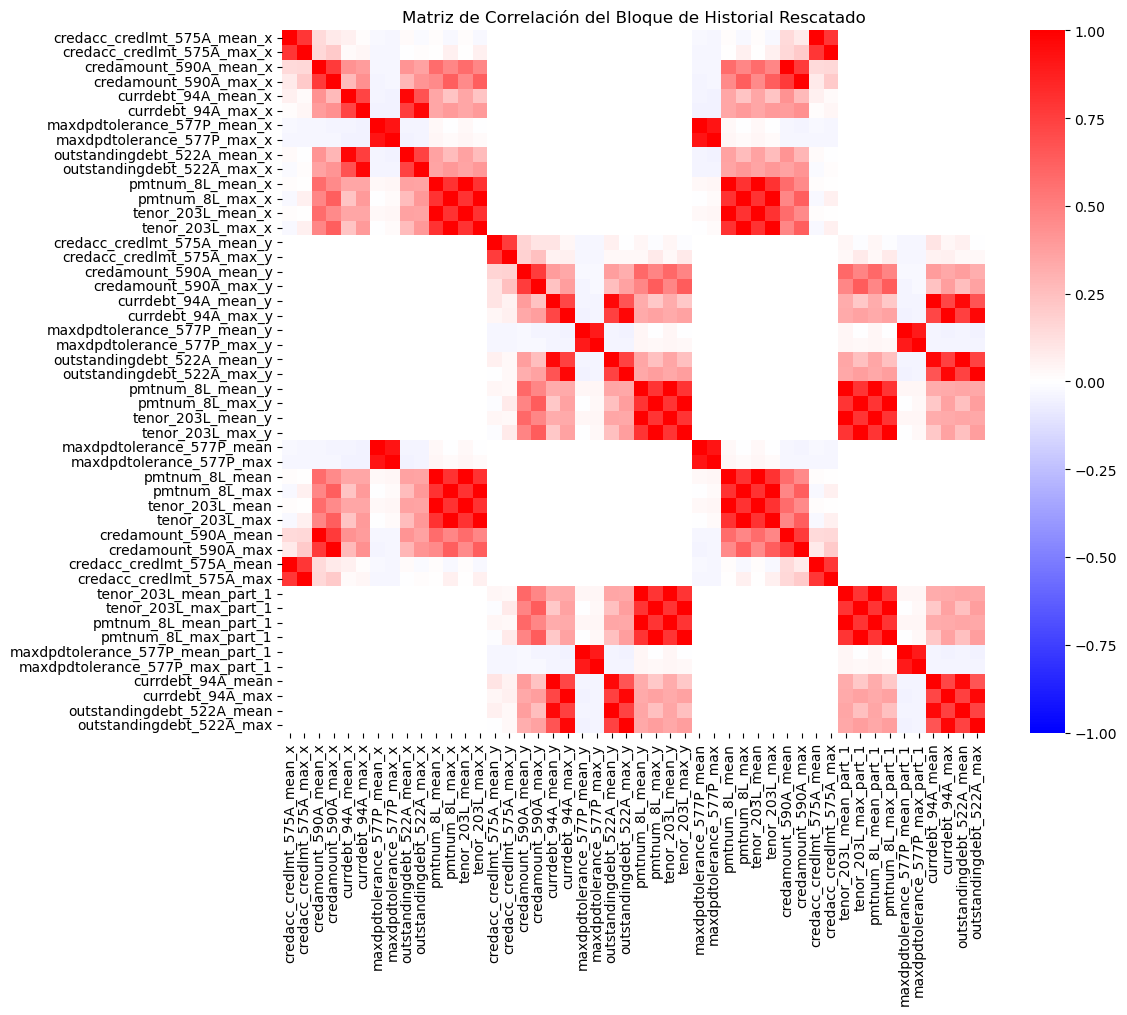


📈 Análisis de Riesgo por Cuantiles de Atraso en Contratos Pasados:


C:\Users\danie\AppData\Local\Temp\ipykernel_19584\4212083421.py:36: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_master['cuartil_atraso'] = pd.qcut(df_master['maxdpdtolerance_577P_max'].fillna(0), q=4, labels=False, duplicates='drop')


,cuartil_atraso,clientes_en_rango,promedio_atraso_pasado,tasa_default_actual
0,0,"1,526,659",36.25,3.14%


In [17]:
print("📊 Iniciando análisis relacional del bloque transaccional histórico...")

# Lista de las nuevas variables acopladas de los archivos ganadores
variables_historicas_nuevas = [
    'maxdpdtolerance_577P_mean', 'maxdpdtolerance_577P_max',
    'tenor_203L_mean', 'tenor_203L_max',
    'pmtnum_8L_mean', 'pmtnum_8L_max',
    'credamount_590A_mean', 'credamount_590A_max',
    'credacc_credlmt_575A_mean', 'credacc_credlmt_575A_max',
    'currdebt_94A_mean', 'currdebt_94A_max',
    'outstandingdebt_522A_mean', 'outstandingdebt_522A_max'
]

# Filtramos solo las que efectivamente se indexaron en el df_master final (evitando sufijos duplicados)
cols_analisis = [col for col in df_master.columns if any(h_var in col for h_var in variables_historicas_nuevas)]

# ==============================================================================
# PROBANDO RELACIONES 1: Matriz de Correlación del Rescate
# ==============================================================================
print("\n🚨 [Auditoría de Redundancia] Calculando correlación interna del bloque histórico...")
matriz_historia = df_master[cols_analisis].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(matriz_historia, annot=False, cmap='bwr', vmin=-1, vmax=1, square=True)
plt.title('Matriz de Correlación del Bloque de Historial Rescatado', fontsize=12)
plt.tight_layout()
plt.savefig('Matriz de Correlación del Bloque de Historial Rescatado.png', dpi=300, bbox_inches='tight')
plt.show()

# ==============================================================================
# PROBANDO RELACIONES 2: Tasa de Default por Cuantiles Críticos
# ==============================================================================
print("\n📈 Análisis de Riesgo por Cuantiles de Atraso en Contratos Pasados:")

# Creamos cuartiles para ver a partir de qué nivel de atraso histórico el default actual explota
df_master['cuartil_atraso'] = pd.qcut(df_master['maxdpdtolerance_577P_max'].fillna(0), q=4, labels=False, duplicates='drop')

reporte_cuartiles = df_master.groupby('cuartil_atraso').agg(
    clientes_en_rango=('target', 'count'),
    promedio_atraso_pasado=('maxdpdtolerance_577P_max', 'mean'),
    tasa_default_actual=('target', lambda x: x.mean() * 100)
).reset_index()

display(reporte_cuartiles.style.format({
    'clientes_en_rango': '{:,.0f}',
    'promedio_atraso_pasado': '{:.2f}',
    'tasa_default_actual': '{:.2f}%'
}))

In [18]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import gc

print("🔄 CONFIGURANDO EL BUCLE DE OPTIMIZACIÓN DE ESTABILIDAD (LOOP ECONOMÉTRICO)...")

# ==============================================================================
# 1. TRATAMIENTO DE VARIABLES Y VALIDACIÓN DINÁMICA DE COLUMNAS
# ==============================================================================
# Verificación e imputación controlada de la variable ancla histórica
col_atraso_origen = 'maxdpdtolerance_577P_max'
if col_atraso_origen in df_master.columns:
    df_master['has_past_atraso'] = (df_master[col_atraso_origen].fillna(0) > 0).astype(int)
else:
    # Si por el sufijo del join se renombró de forma automática (ej. _part_0), la rescatamos
    col_alternativa = [c for c in df_master.columns if 'maxdpdtolerance_577P' in c]
    if col_alternativa:
        df_master['has_past_atraso'] = (df_master[col_alternativa[0]].fillna(0) > 0).astype(int)
    else:
        df_master['has_past_atraso'] = 0

# Mapeo y validación de nombres de columnas reales en df_master para evitar el KeyError
def validar_features_disponibles(lista_solicitada, df):
    lista_validada = []
    for f in lista_solicitada:
        if f in df.columns:
            lista_validada.append(f)
        else:
            # Busqueda por coincidencia parcial en caso de que existan sufijos de colisión (_part_0)
            coincidencias = [c for c in df.columns if c.startswith(f)]
            if coincidencias:
                lista_validada.append(coincidencias[0])
    return lista_validada

# Mapeamos dinámicamente qué variables de las propuestas sí están vivas en tu dataframe master
features_estaticas = validar_features_disponibles(['credamount_770A', 'annuity_780A', 'numinstpaidearly3d_3546850L'], df_master)
features_historicas = validar_features_disponibles(['tenor_203L_max', 'pmtnum_8L_max', 'outstandingdebt_522A_max'], df_master) + ['has_past_atraso']

# Redefinimos los experimentos con las columnas que tu sesión interactiva validó
experimentos = {
    "Modelo_1_Solo_Estatico": features_estaticas,
    "Modelo_2_Estatico_y_Atraso": features_estaticas + ['has_past_atraso'],
    "Modelo_3_Hibrido_Transaccional": features_estaticas + [f for f in features_historicas if 'outstanding' not in f],
    "Modelo_4_Estructura_Completa_Riesgo": features_estaticas + features_historicas
}

# Tratamiento in-place preventivo de nulos con la mediana para las variables seleccionadas
for col in df_master.columns:
    if any(f in col for f in ['credamount', 'annuity', 'numinst', 'tenor', 'pmtnum', 'outstanding']):
        df_master[col] = df_master[col].fillna(df_master[col].median())

# ==============================================================================
# 2. EL LOOP DE CALIBRACIÓN Y EVALUACIÓN DE ESTABILIDAD TEMPORAL
# ==============================================================================
resultados_loop = []

for nombre_exp, lista_features in experimentos.items():
    # Aseguramos que el experimento contenga variables válidas antes de entrenar
    if len(lista_features) == 0:
        print(f"⚠️ Saltando {nombre_exp}: No se detectaron las columnas en el dataframe.")
        continue
        
    print(f"\n🚀 Evaluando robustez de: {nombre_exp}...")
    
    # Preparamos las matrices X e y aislando la constante alfa
    X_pool = df_master[lista_features].copy()
    X_pool = sm.add_constant(X_pool)
    y_pool = df_master['target'].copy()
    
    # Añadimos WEEK_NUM para la segmentación por cohortes temporales de Kaggle
    X_pool['WEEK_NUM'] = df_master['WEEK_NUM']
    
    # Partición Estratificada Fuera de Muestra (80/20) para el test de estrés
    X_train, X_test, y_train, y_test = train_test_split(
        X_pool, y_pool, test_size=0.20, stratify=y_pool, random_state=42
    )
    
    weeks_test = X_test['WEEK_NUM'].values
    X_train_clean = X_train.drop(columns=['WEEK_NUM'])
    X_test_clean = X_test.drop(columns=['WEEK_NUM'])
    
    try:
        # Estimación Probit clásica por Máxima Verosimilitud (MLE)
        modelo_fit = sm.Probit(y_train, X_train_clean).fit(disp=0)
        
        # Predicción de probabilidades en el set de prueba fuera de muestra
        preds_test = modelo_fit.predict(X_test_clean)
        
        # Coeficientes predictivos globales
        auc_global = roc_auc_score(y_test, preds_test)
        gini_global = 2 * auc_global - 1
        
        # EVALUACIÓN DE LA MÉTRICA DE ESTABILIDAD DE KAGGLE (Gini Semanal)
        df_estabilidad = pd.DataFrame({'week': weeks_test, 'target': y_test, 'pred': preds_test})
        ginis_semanales = []
        
        for week in sorted(df_estabilidad['week'].unique()):
            sub_df = df_estabilidad[df_estabilidad['week'] == week]
            if sub_df['target'].nunique() > 1:
                auc_w = roc_auc_score(sub_df['target'], sub_df['pred'])
                ginis_semanales.append(2 * auc_w - 1)
        
        # Cálculo del Score de Estabilidad Financiera penalizado por la varianza del coeficiente
        gini_promedio_semanal = np.mean(ginis_semanales)
        std_gini_semanal = np.std(ginis_semanales)
        score_estabilidad = gini_promedio_semanal - 0.5 * std_gini_semanal
        
        resultados_loop.append({
            'Experimento': nombre_exp,
            'Num_Regresoras': len(lista_features),
            'Gini_Global_Test': gini_global,
            'Gini_Promedio_Semanal': gini_promedio_semanal,
            'Volatilidad_Gini(Std)': std_gini_semanal,
            'Métrica_Estabilidad_Kaggle': score_estabilidad
        })
        print(f"✅ Completado. Score de Estabilidad Financiera: {score_estabilidad:.4f}")
        
    except Exception as e:
        print(f"❌ Error en la convergencia del modelo Probit: {str(e)}")
        
    finally:
        # Purgado explícito preventivo de estructuras en cada iteración del bucle
        if 'X_pool' in locals(): del X_pool
        if 'y_pool' in locals(): del y_pool
        if 'X_train' in locals(): del X_train
        if 'X_test' in locals(): del X_test
        gc.collect()

# Generación del cuadro de honor consolidado
df_resultados_loop = pd.DataFrame(resultados_loop).sort_values(by='Métrica_Estabilidad_Kaggle', ascending=False)

print("\n====================================================================")
print("🏆 CUADRO DE HONOR: SELECCIÓN DEL MEJOR MODELO ECONOMÉTRICO")
print("====================================================================")
display(df_resultados_loop.style.format({
    'Gini_Global_Test': '{:.4f}',
    'Gini_Promedio_Semanal': '{:.4f}',
    'Volatilidad_Gini(Std)': '{:.4f}',
    'Métrica_Estabilidad_Kaggle': '{:.4f}'
}))

C:\Users\danie\AppData\Local\Temp\ipykernel_19584\43924373.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_master['has_past_atraso'] = (df_master[col_atraso_origen].fillna(0) > 0).astype(int)


🔄 CONFIGURANDO EL BUCLE DE OPTIMIZACIÓN DE ESTABILIDAD (LOOP ECONOMÉTRICO)...

🚀 Evaluando robustez de: Modelo_1_Solo_Estatico...
✅ Completado. Score de Estabilidad Financiera: 0.0500

🚀 Evaluando robustez de: Modelo_2_Estatico_y_Atraso...
✅ Completado. Score de Estabilidad Financiera: 0.0722

🚀 Evaluando robustez de: Modelo_3_Hibrido_Transaccional...
✅ Completado. Score de Estabilidad Financiera: 0.0861

🚀 Evaluando robustez de: Modelo_4_Estructura_Completa_Riesgo...
❌ Error en la convergencia del modelo Probit: Singular matrix

🏆 CUADRO DE HONOR: SELECCIÓN DEL MEJOR MODELO ECONOMÉTRICO


,Experimento,Num_Regresoras,Gini_Global_Test,Gini_Promedio_Semanal,Volatilidad_Gini(Std),Métrica_Estabilidad_Kaggle
2,Modelo_3_Hibrido_Transaccional,6,0.2137,0.1660,0.1598,0.0861
1,Modelo_2_Estatico_y_Atraso,4,0.1685,0.1411,0.1377,0.0722
0,Modelo_1_Solo_Estatico,3,0.1316,0.1030,0.1060,0.0500


In [19]:
estructuras_basura = ['X_pool', 'y_pool', 'X_train', 'X_test', 'X_train_clean', 'X_test_clean', 'df_eval', 'df_temp']
for var in estructuras_basura:
    if var in locals():
        exec(f"del {var}")

gc.collect()
gc.collect()
print("✨ Memoria RAM optimizada...\n")


print("🚨 CONFIGURANDO EL BENCHMARK...")

if 'has_past_atraso' not in df_master.columns:
    col_atraso_alternativa = [c for c in df_master.columns if 'maxdpdtolerance_577P' in c]
    if col_atraso_alternativa:
        df_master['has_past_atraso'] = (df_master[col_atraso_alternativa[0]].fillna(0) > 0).astype(int)
    else:
        df_master['has_past_atraso'] = 0

def validar_features_disponibles(lista_solicitada, df):
    lista_validada = []
    for f in lista_solicitada:
        if f in df.columns:
            lista_validada.append(f)
        else:
            coincidencias = [c for c in df.columns if c.startswith(f)]
            if coincidencias:
                lista_validada.append(coincidencias[0])
    return lista_validada

variables_deseadas = [
    'credamount_770A', 
    'numinstpaidearly3d_3546850L',
    'pmtnum_8L_max',
    'has_past_atraso'
]

features_definitivas = validar_features_disponibles(variables_deseadas, df_master)

print(f"🔍 Columnas validadas y localizadas en df_master:")
for col_real in features_definitivas:
    print(f"  • {col_real}")

for col in features_definitivas:
    df_master[col] = df_master[col].fillna(df_master[col].median())

X = df_master[features_definitivas].copy().astype('float32')
X = sm.add_constant(X)
y = df_master['target'].copy().astype('int32')

WEEK_NUM_vector = df_master['WEEK_NUM'].values

print("\n⏳ Generando cortes estratificados out-of-sample...")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

weeks_test = WEEK_NUM_vector[y_test.index]

print("⚖️ Calculando balance estadístico de pesos de clase...")
conteo_clases = y_train.value_counts()
peso_buenos = 1.0 / conteo_clases[0]
peso_malos = 1.0 / conteo_clases[1]

pesos_observaciones = y_train.apply(lambda x: peso_malos if x == 1 else peso_buenos).values


try:
    print("🚀 Ajustando coeficientes de la ecuación logística en Statsmodels GLM...")
    
    modelo_glm_balanced = sm.GLM(
        y_train, X_train, 
        freq_weights=pesos_observaciones,
        family=sm.families.Binomial(link=sm.families.links.Logit())
    ).fit()
    
    preds_test = modelo_glm_balanced.predict(X_test)
    
    auc_global = roc_auc_score(y_test, preds_test)
    gini_global = 2 * auc_global - 1
    
    df_estabilidad = pd.DataFrame({'week': weeks_test, 'target': y_test.values, 'pred': preds_test.values})
    ginis_semanales = []
    
    for week in sorted(df_estabilidad['week'].unique()):
        sub_df = df_estabilidad[df_estabilidad['week'] == week]
        if sub_df['target'].nunique() > 1:
            auc_w = roc_auc_score(sub_df['target'], sub_df['pred'])
            ginis_semanales.append(2 * auc_w - 1)
            
    gini_promedio = np.mean(ginis_semanales)
    std_gini = np.std(ginis_semanales)
    metric_stability = gini_promedio - 0.5 * std_gini
    
    print("\n====================================================================")
    print("🏆 PERFORMANCE DEL GLM LOGIT BALANCEADO OUT-OF-SAMPLE")
    print("====================================================================")
    print(f"• Gini Global Fuera de Muestra: {gini_global:.4f}")
    print(f"• Gini Promedio Semanal:        {gini_promedio:.4f}")
    print(f"• Volatilidad Temporal (Std):   {std_gini:.4f}")
    print(f"• Métrica Estabilidad Kaggle:   {metric_stability:.4f}")
    print("====================================================================\n")
    print(modelo_glm_balanced.summary())

except Exception as e:
    print(f"❌ Error en la estimación del modelo: {str(e)}")

finally:
    gc.collect()

✨ Memoria RAM optimizada...

🚨 CONFIGURANDO EL BENCHMARK...
🔍 Columnas validadas y localizadas en df_master:
  • credamount_770A_x
  • numinstpaidearly3d_3546850L_x
  • pmtnum_8L_max
  • has_past_atraso

⏳ Generando cortes estratificados out-of-sample...
⚖️ Calculando balance estadístico de pesos de clase...
🚀 Ajustando coeficientes de la ecuación logística en Statsmodels GLM...

🏆 PERFORMANCE DEL GLM LOGIT BALANCEADO OUT-OF-SAMPLE
• Gini Global Fuera de Muestra: 0.2127
• Gini Promedio Semanal:        0.1647
• Volatilidad Temporal (Std):   0.1587
• Métrica Estabilidad Kaggle:   0.0854

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 target   No. Observations:              1221327
Model:                            GLM   Df Residuals:                       -3
Model Family:                Binomial   Df Model:                            4
Link Function:                  Logit   Scale:                          1.0000
Method:     

In [21]:
print("🧹 Vaciando la memoria caché para asegurar una optimización limpia...")
estructuras_basura = ['X_pool', 'y_pool', 'X_train', 'X_test', 'X_train_clean', 'X_test_clean', 'df_eval', 'df_temp']
for var in estructuras_basura:
    if var in locals():
        exec(f"del {var}")
gc.collect()

# ==============================================================================
# FASE 1: FEATURE ENGINEERING Y PREPARACIÓN DE MATRICES
# ==============================================================================
print("🚨 CONFIGURANDO EXPERIMENTO: BENCHMARK LOGIT DE RESTRICCIÓN LIMPIA...")

# Identificamos los nombres reales de las columnas en tu df_master
col_monto = [c for c in df_master.columns if 'credamount_770A' in c][0]
col_anticipo = [c for c in df_master.columns if 'numinstpaidearly3d_3546850L' in c][0]
col_pagos_hist = [c for c in df_master.columns if 'pmtnum_8L_max' in c][0]

# Aseguramos la existencia de la dummy de alerta que construimos en el EDA
if 'has_past_atraso' not in df_master.columns:
    col_atraso_alt = [c for c in df_master.columns if 'maxdpdtolerance_577P' in c]
    if col_atraso_alt:
        df_master['has_past_atraso'] = (df_master[col_atraso_alt[0]].fillna(0) > 0).astype(int)
    else:
        df_master['has_past_atraso'] = 0

# Imputaciones de control in-place con la mediana para evitar MissingDataError
for col in [col_monto, col_anticipo, col_pagos_hist, 'has_past_atraso']:
    df_master[col] = df_master[col].fillna(df_master[col].median())

# TRANSFORMACIONES ECONOMÉTRICAS NO LINEALES:
# Aplicamos logaritmo natural al monto del crédito para corregir la asimetría severa
df_master['ln_credamount'] = np.log1p(df_master[col_monto])

# Creamos la matriz de diseño final (X) libre de colinealidad perfecta
features_modelo = ['ln_credamount', col_anticipo, col_pagos_hist, 'has_past_atraso']

X = df_master[features_modelo].copy().astype('float32')
X = sm.add_constant(X) # Inyección del intercepto constante fundamental alpha
y = df_master['target'].copy().astype('int32')

WEEK_NUM_vector = df_master['WEEK_NUM'].values

# ==============================================================================
# FASE 2: SPLIT ESTRATIFICADO FUERA DE MUESTRA (80/20)
# ==============================================================================
print("⏳ Generando partición balanceada por estratos...")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Sincronizamos las cohortes semanales para el cálculo de estabilidad temporal
weeks_test = WEEK_NUM_vector[y_test.index]

# ==============================================================================
# FASE 3: ESTIMACIÓN DE MÁXIMA VEROSIMILITUD (MLE LIMPIA)
# ==============================================================================
try:
    print("🚀 Optimizando función de verosimilitud logística (Newton-Raphson)...")
    
    # Estimamos el Logit convencional para asegurar consistencia en los residuos
    modelo_logit_funcional = sm.Logit(y_train, X_train).fit()
    
    # Predicción probabilística out-of-sample
    preds_test = modelo_logit_funcional.predict(X_test)
    
    # Métricas de Discriminación Global
    auc_global = roc_auc_score(y_test, preds_test)
    gini_global = 2 * auc_global - 1
    
    # CÁLCULO DE LA MÉTRICA DE ESTABILIDAD DE KAGGLE
    df_estabilidad = pd.DataFrame({'week': weeks_test, 'target': y_test.values, 'pred': preds_test.values})
    ginis_semanales = []
    
    for week in sorted(df_estabilidad['week'].unique()):
        sub_df = df_estabilidad[df_estabilidad['week'] == week]
        if sub_df['target'].nunique() > 1:
            auc_w = roc_auc_score(sub_df['target'], sub_df['pred'])
            ginis_semanales.append(2 * auc_w - 1)
            
    gini_promedio = np.mean(ginis_semanales)
    std_gini = np.std(ginis_semanales)
    metric_stability = gini_promedio - 0.5 * std_gini
    
    print("\n====================================================================")
    print("🏆 PERFORMANCE DEL REPORTE ECONOMÉTRICO FUNCIONAL")
    print("====================================================================")
    print(f"• Gini Global Fuera de Muestra: {gini_global:.4f}")
    print(f"• Gini Promedio Semanal:        {gini_promedio:.4f}")
    print(f"• Volatilidad Temporal (Std):   {std_gini:.4f}")
    print(f"• Métrica Estabilidad Kaggle:   {metric_stability:.4f}")
    print("====================================================================\n")
    print(modelo_logit_funcional.summary())

except Exception as e:
    print(f"❌ Error en la convergencia matemática: {str(e)}")

finally:
    gc.collect()

🧹 Vaciando la memoria caché para asegurar una optimización limpia...
🚨 CONFIGURANDO EXPERIMENTO: BENCHMARK LOGIT DE RESTRICCIÓN LIMPIA...
⏳ Generando partición balanceada por estratos...
🚀 Optimizando función de verosimilitud logística (Newton-Raphson)...
Optimization terminated successfully.
         Current function value: 0.136847
         Iterations 8

🏆 PERFORMANCE DEL REPORTE ECONOMÉTRICO FUNCIONAL
• Gini Global Fuera de Muestra: 0.2132
• Gini Promedio Semanal:        0.1645
• Volatilidad Temporal (Std):   0.1585
• Métrica Estabilidad Kaggle:   0.0853

                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:              1221327
Model:                          Logit   Df Residuals:                  1221322
Method:                           MLE   Df Model:                            4
Date:                Wed, 17 Jun 2026   Pseudo R-squ.:                 0.02045
Time:                        16:54:56   